## Task 1 - Singly Linked List

Each node stores an integer and a reference to the next node. The list maintains only `head`; the last node has `next = None`. New nodes are created when values are inserted.

`INSERT_AFTER` and `DELETE_VALUE` act on the first matching node and return `False` if the key is absent. `DELETE_FRONT` returns the removed value and raises `IndexError` for an empty list. Display methods return a string that is printed by the trace code.


In [1]:
class Node:
    def __init__(self, data):
        self.data = data
        self.next = None


class SinglyLinkedList:
    def __init__(self):
        self.head = None

    def insert_front(self, value):
        node = Node(value)
        node.next = self.head
        self.head = node

    def insert_end(self, value):
        node = Node(value)
        if self.head is None:
            self.head = node
            return
        current = self.head
        while current.next is not None:
            current = current.next
        current.next = node

    def insert_after(self, key, value):
        current = self.head
        while current is not None:
            if current.data == key:
                node = Node(value)
                node.next = current.next
                current.next = node
                return True
            current = current.next
        return False

    def delete_front(self):
        if self.head is None:
            raise IndexError('Cannot delete from an empty list')
        node = self.head
        self.head = node.next
        node.next = None
        return node.data

    def delete_value(self, value):
        previous = None
        current = self.head
        while current is not None:
            if current.data == value:
                if previous is None:
                    self.head = current.next
                else:
                    previous.next = current.next
                current.next = None
                return True
            previous = current
            current = current.next
        return False

    def search(self, value):
        current = self.head
        while current is not None:
            if current.data == value:
                return True
            current = current.next
        return False

    def contents(self):
        values = []
        current = self.head
        while current is not None:
            values.append(current.data)
            current = current.next
        return values

    def display(self):
        return ' -> '.join(str(value) for value in self.contents()) + ' -> NULL' if self.head else 'NULL'


In [2]:
singly = SinglyLinkedList()
singly_operations = [
    ('INSERT_FRONT', (30,)), ('INSERT_FRONT', (20,)),
    ('INSERT_FRONT', (10,)), ('INSERT_END', (40,)),
    ('INSERT_END', (50,)), ('INSERT_AFTER', (30, 35)),
    ('DISPLAY', ()), ('SEARCH', (35,)), ('SEARCH', (100,)),
    ('DELETE_FRONT', ()), ('DELETE_VALUE', (40,)),
    ('DELETE_VALUE', (100,)), ('INSERT_FRONT', (5,)), ('DISPLAY', ()),
]
singly_trace = []
print(f"{'Operation':<23} {'List after operation':<44} {'Head':>5}  Result")
print('-' * 100)
for operation, arguments in singly_operations:
    label = f"{operation}({', '.join(map(str, arguments))})"
    if operation == 'INSERT_FRONT':
        singly.insert_front(*arguments)
        result = 'Inserted'
    elif operation == 'INSERT_END':
        singly.insert_end(*arguments)
        result = 'Inserted'
    elif operation == 'INSERT_AFTER':
        result = 'Inserted' if singly.insert_after(*arguments) else 'Key not found'
    elif operation == 'DELETE_FRONT':
        result = f'Deleted {singly.delete_front()}'
    elif operation == 'DELETE_VALUE':
        result = 'Deleted' if singly.delete_value(*arguments) else 'Value not found'
    elif operation == 'SEARCH':
        result = 'Found' if singly.search(*arguments) else 'Not found'
    else:
        result = 'Forward traversal'
    head_value = singly.head.data if singly.head is not None else None
    singly_trace.append((label, singly.contents(), head_value, result))
    print(f'{label:<23} {singly.display():<44} {str(head_value):>5}  {result}')

assert singly.contents() == [5, 20, 30, 35, 50]
assert singly.search(35) and not singly.search(100)


Operation               List after operation                          Head  Result
----------------------------------------------------------------------------------------------------
INSERT_FRONT(30)        30 -> NULL                                      30  Inserted
INSERT_FRONT(20)        20 -> 30 -> NULL                                20  Inserted
INSERT_FRONT(10)        10 -> 20 -> 30 -> NULL                          10  Inserted
INSERT_END(40)          10 -> 20 -> 30 -> 40 -> NULL                    10  Inserted
INSERT_END(50)          10 -> 20 -> 30 -> 40 -> 50 -> NULL              10  Inserted
INSERT_AFTER(30, 35)    10 -> 20 -> 30 -> 35 -> 40 -> 50 -> NULL        10  Inserted
DISPLAY()               10 -> 20 -> 30 -> 35 -> 40 -> 50 -> NULL        10  Forward traversal
SEARCH(35)              10 -> 20 -> 30 -> 35 -> 40 -> 50 -> NULL        10  Found
SEARCH(100)             10 -> 20 -> 30 -> 35 -> 40 -> 50 -> NULL        10  Not found
DELETE_FRONT()          20 -> 30 -> 35 -> 40

### Node Connections

The final singly linked list is:

```text
HEAD
 |
 v
[5] -> [20] -> [30] -> [35] -> [50] -> NULL
```

### Answers - Part C

1. **Purpose of head:** It references the first node and provides the starting point for traversal. `head = None` represents an empty list.
2. **Why a next reference?** Nodes can occupy unrelated memory locations. The reference connects each node to its successor.
3. **Beginning versus end insertion:** Front insertion changes two references and takes `Θ(1)` time. End insertion starts from head and follows the links to the last node, so its worst-case time is `Θ(n)` when no tail is stored.
4. **Deleting the head:** Head must first be moved to the next node. Otherwise the remaining chain could become inaccessible. Deleting the only node makes head `None`.
5. **Search complexity:** Worst-case `Θ(n)`, because the target can be last or absent. A match at the head takes `Θ(1)`.


## Task 2 - Doubly Linked List

Each node stores `data`, `prev`, and `next`. The list maintains both head and tail. The first node has `prev = None`, and the last has `next = None`.

Front and end deletion return the removed value and raise `IndexError` when the list is empty. Deletion by value removes the first match and reports whether a node was found. Removed nodes have their links cleared.


In [3]:
class DoublyNode:
    def __init__(self, data):
        self.data = data
        self.prev = None
        self.next = None


class DoublyLinkedList:
    def __init__(self):
        self.head = None
        self.tail = None

    def insert_front(self, value):
        node = DoublyNode(value)
        node.next = self.head
        if self.head is None:
            self.tail = node
        else:
            self.head.prev = node
        self.head = node

    def insert_end(self, value):
        node = DoublyNode(value)
        node.prev = self.tail
        if self.tail is None:
            self.head = node
        else:
            self.tail.next = node
        self.tail = node

    def _remove(self, node):
        if node.prev is None:
            self.head = node.next
        else:
            node.prev.next = node.next
        if node.next is None:
            self.tail = node.prev
        else:
            node.next.prev = node.prev
        node.prev = None
        node.next = None
        return node.data

    def delete_front(self):
        if self.head is None:
            raise IndexError('Cannot delete from an empty list')
        return self._remove(self.head)

    def delete_end(self):
        if self.tail is None:
            raise IndexError('Cannot delete from an empty list')
        return self._remove(self.tail)

    def delete_value(self, value):
        current = self.head
        while current is not None:
            if current.data == value:
                self._remove(current)
                return True
            current = current.next
        return False

    def contents(self, backward=False):
        values = []
        current = self.tail if backward else self.head
        while current is not None:
            values.append(current.data)
            current = current.prev if backward else current.next
        return values

    def display_forward(self):
        return ' <-> '.join(map(str, self.contents())) if self.head else 'Empty'

    def display_backward(self):
        return ' <-> '.join(map(str, self.contents(backward=True))) if self.tail else 'Empty'


doubly = DoublyLinkedList()
doubly_operations = [
    ('INSERT_END', (10,)), ('INSERT_END', (20,)), ('INSERT_END', (30,)),
    ('INSERT_FRONT', (5,)), ('INSERT_END', (40,)),
    ('DISPLAY_FORWARD', ()), ('DISPLAY_BACKWARD', ()),
    ('DELETE_FRONT', ()), ('DELETE_END', ()), ('INSERT_FRONT', (2,)),
    ('DELETE_VALUE', (20,)), ('DISPLAY_FORWARD', ()), ('DISPLAY_BACKWARD', ()),
]
doubly_trace = []
print(f"{'Operation':<23} {'Traversal order':<30} {'Head':>5} {'Tail':>5}  Result")
print('-' * 90)
for operation, arguments in doubly_operations:
    label = f"{operation}({', '.join(map(str, arguments))})"
    if operation == 'INSERT_FRONT':
        doubly.insert_front(*arguments)
        result = 'Inserted'
    elif operation == 'INSERT_END':
        doubly.insert_end(*arguments)
        result = 'Inserted'
    elif operation == 'DELETE_FRONT':
        result = f'Deleted {doubly.delete_front()}'
    elif operation == 'DELETE_END':
        result = f'Deleted {doubly.delete_end()}'
    elif operation == 'DELETE_VALUE':
        result = 'Deleted' if doubly.delete_value(*arguments) else 'Value not found'
    else:
        result = 'Backward' if operation == 'DISPLAY_BACKWARD' else 'Forward'
    traversal = doubly.display_backward() if operation == 'DISPLAY_BACKWARD' else doubly.display_forward()
    head_value = doubly.head.data if doubly.head is not None else None
    tail_value = doubly.tail.data if doubly.tail is not None else None
    doubly_trace.append((label, doubly.contents(), doubly.contents(True)))
    print(f'{label:<23} {traversal:<30} {str(head_value):>5} {str(tail_value):>5}  {result}')

assert doubly.contents() == [2, 10, 30]
assert doubly.contents(backward=True) == [30, 10, 2]


Operation               Traversal order                 Head  Tail  Result
------------------------------------------------------------------------------------------
INSERT_END(10)          10                                10    10  Inserted
INSERT_END(20)          10 <-> 20                         10    20  Inserted
INSERT_END(30)          10 <-> 20 <-> 30                  10    30  Inserted
INSERT_FRONT(5)         5 <-> 10 <-> 20 <-> 30             5    30  Inserted
INSERT_END(40)          5 <-> 10 <-> 20 <-> 30 <-> 40      5    40  Inserted
DISPLAY_FORWARD()       5 <-> 10 <-> 20 <-> 30 <-> 40      5    40  Forward
DISPLAY_BACKWARD()      40 <-> 30 <-> 20 <-> 10 <-> 5      5    40  Backward
DELETE_FRONT()          10 <-> 20 <-> 30 <-> 40           10    40  Deleted 5
DELETE_END()            10 <-> 20 <-> 30                  10    30  Deleted 40
INSERT_FRONT(2)         2 <-> 10 <-> 20 <-> 30             2    30  Inserted
DELETE_VALUE(20)        2 <-> 10 <-> 30                    2  

### Node Connections After INSERT_END(40)

```text
        HEAD                               TAIL
         |                                  |
         v                                  v
NULL <- [5] <-> [10] <-> [20] <-> [30] <-> [40] -> NULL
```

Each arrow to the right is a `next` reference; each arrow to the left is a `prev` reference.

| Node data | Previous node | Next node |
|---:|---:|---:|
| 5 | `None` | 10 |
| 10 | 5 | 20 |
| 20 | 10 | 30 |
| 30 | 20 | 40 |
| 40 | 30 | `None` |

### Answers - Part C

1. **Main difference:** A singly linked node has only a next reference. A doubly linked node also stores a previous reference.
2. **Traversal in both directions:** Following next from head gives forward order; following prev from tail gives backward order.
3. **Additional memory:** Each node requires one extra reference for prev. The doubly linked list also stores a tail reference. Both structures still require `Θ(n)` total storage.
4. **Efficient last-node deletion:** Tail identifies the last node, and `tail.prev` identifies its predecessor directly. Deleting the last node therefore takes `Θ(1)` time.
5. **Incorrect updates:** A broken link can lose part of the list, create an unintended cycle, or make forward and backward traversals disagree. Head and tail must also be updated when the last remaining node is removed.


## Task 3 - Circular Linked List and Josephus Problem

### Part A - Circular Linked List

The circular list reuses `Node` and maintains head and tail. In a nonempty list, `tail.next` always references head. A single node points to itself. Traversal stops when it returns to head after one complete cycle.

`DELETE_VALUE` removes the first match. The `_delete_after` helper unlinks a node when its predecessor is already known, avoiding another search during Josephus elimination.


In [4]:
class CircularLinkedList:
    def __init__(self):
        self.head = None
        self.tail = None

    def insert_end(self, value):
        node = Node(value)
        if self.head is None:
            self.head = node
            self.tail = node
            node.next = node
        else:
            node.next = self.head
            self.tail.next = node
            self.tail = node

    def _delete_after(self, previous):
        node = previous.next
        if node is previous:
            self.head = None
            self.tail = None
        else:
            previous.next = node.next
            if node is self.head:
                self.head = node.next
            if node is self.tail:
                self.tail = previous
        node.next = None
        return node.data

    def delete_value(self, value):
        if self.head is None:
            return False
        previous = self.tail
        current = self.head
        while True:
            if current.data == value:
                self._delete_after(previous)
                return True
            previous = current
            current = current.next
            if current is self.head:
                return False

    def search(self, value):
        if self.head is None:
            return False
        current = self.head
        while True:
            if current.data == value:
                return True
            current = current.next
            if current is self.head:
                return False

    def contents(self):
        if self.head is None:
            return []
        values = []
        current = self.head
        while True:
            values.append(current.data)
            current = current.next
            if current is self.head:
                return values

    def display(self):
        if self.head is None:
            return 'Empty'
        return ' -> '.join(map(str, self.contents())) + ' -> HEAD'


circular = CircularLinkedList()
print('Empty list:', circular.display())
for value in [10, 20, 30, 40]:
    circular.insert_end(value)
    print(f'INSERT_END({value}): {circular.display()}')
print('SEARCH(30):', circular.search(30))
print('SEARCH(100):', circular.search(100))
for value in [10, 40, 100, 20, 30]:
    deleted = circular.delete_value(value)
    print(f'DELETE_VALUE({value}): {deleted}; {circular.display()}')
assert circular.head is None and circular.tail is None


Empty list: Empty
INSERT_END(10): 10 -> HEAD
INSERT_END(20): 10 -> 20 -> HEAD
INSERT_END(30): 10 -> 20 -> 30 -> HEAD
INSERT_END(40): 10 -> 20 -> 30 -> 40 -> HEAD
SEARCH(30): True
SEARCH(100): False
DELETE_VALUE(10): True; 20 -> 30 -> 40 -> HEAD
DELETE_VALUE(40): True; 20 -> 30 -> HEAD
DELETE_VALUE(100): False; 20 -> 30 -> HEAD
DELETE_VALUE(20): True; 30 -> HEAD
DELETE_VALUE(30): True; Empty


### Circular Node Connections

After inserting `10`, `20`, `30`, and `40`:

```text
HEAD                    TAIL
 |                       |
 v                       v
[10] -> [20] -> [30] -> [40]
 ^                       |
 |_______________________|
```

The last next reference returns to head. After all but one node are removed, that node's next reference returns to itself. Deleting the only node sets both head and tail to `None`.

### Part B - Josephus Problem

People are numbered from `1` to `n`. The current person counts as one, so advancing `k - 1` links identifies the next person to eliminate. The previous node is retained so removal takes constant time. Counting resumes at the removed person's successor.


In [5]:
def josephus(n, k, trace=False):
    if type(n) is not int or type(k) is not int or n < 1 or k < 1:
        raise ValueError('n and k must be positive integers.')
    circle = CircularLinkedList()
    for person in range(1, n + 1):
        circle.insert_end(person)
    if trace:
        print('Initial circle:', circle.display())
    previous = circle.tail
    current = circle.head
    remaining = n
    eliminated = []
    while remaining > 1:
        for _ in range(k - 1):
            previous = current
            current = current.next
        person = circle._delete_after(previous)
        eliminated.append(person)
        if trace:
            print('Eliminated:', person)
        current = previous.next
        remaining -= 1
    survivor = current.data
    if trace:
        print('Survivor:', survivor)
    circle.delete_value(survivor)
    return eliminated, survivor


elimination_order, survivor = josephus(7, 3, trace=True)
print('Elimination order:', elimination_order)
assert elimination_order == [3, 6, 2, 7, 5, 1]
assert survivor == 4

print(f"\n{'n':>5} {'k':>5} {'Expected survivor':>20} {'Actual survivor':>18}")
print('-' * 51)
for n, k, expected in [(7, 3, 4), (5, 2, 3), (10, 3, 4)]:
    order, actual = josephus(n, k)
    assert actual == expected
    print(f'{n:>5} {k:>5} {expected:>20} {actual:>18}')

assert josephus(5, 1) == ([1, 2, 3, 4], 5)
assert josephus(1, 3) == ([], 1)


Initial circle: 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> HEAD
Eliminated: 3
Eliminated: 6
Eliminated: 2
Eliminated: 7
Eliminated: 5
Eliminated: 1
Survivor: 4
Elimination order: [3, 6, 2, 7, 5, 1]

    n     k    Expected survivor    Actual survivor
---------------------------------------------------
    7     3                    4                  4
    5     2                    3                  3
   10     3                    4                  4


### Answers - Part C

1. **Why a circular list?** The next reference naturally continues from the last person to the first. Removed people are unlinked, so future counting visits only remaining people.
2. **Traversal difference:** A standard singly linked list stops at `None`. A circular list stops after returning to its starting node; waiting for `None` would not terminate on a valid nonempty circle.
3. **When `k = 1`:** No counting links are followed. People `1` through `n - 1` are eliminated in order, and person `n` survives.
4. **When `n = 1`:** No elimination is needed. Person `1` survives for every positive `k`.
5. **Running time of this implementation:** Building the circle takes `Θ(n)` because tail permits constant-time insertion. There are `n - 1` elimination rounds, each with exactly `k - 1` counting transitions, for `(n - 1)(k - 1)` transitions in total. There is also constant work per removal and one move to the next candidate. No search from head is performed during elimination. Total time is `Θ(n + (n - 1)k)`, which is `Θ(nk)` for `n >= 2`. For fixed `k`, it is `Θ(n)`; for `n = 1`, it is `Θ(1)`. Large values of `k` make repeated circuits because the code does not reduce `k` modulo the remaining population.

For `n = 7` and `k = 3`, counting follows 12 links and performs six removals. The program prints only each eliminated person, rather than traversing the remaining circle after every removal. Node storage and the saved elimination order each require `Θ(n)` space.


### Empty Lists and Missing Keys

The checks below cover empty deletion, insertion after a missing key, deletion of the only node, first-match behavior with duplicate values, and reinsertion after a list becomes empty.


In [6]:
empty_singly = SinglyLinkedList()
assert empty_singly.display() == 'NULL'
assert not empty_singly.search(10)
assert not empty_singly.insert_after(10, 20)
assert not empty_singly.delete_value(10)
try:
    empty_singly.delete_front()
except IndexError as error:
    print('Singly:', error)
empty_singly.insert_end(10)
assert empty_singly.delete_value(10) and empty_singly.head is None
empty_singly.insert_front(10)
empty_singly.insert_end(10)
assert empty_singly.insert_after(10, 20)
assert empty_singly.contents() == [10, 20, 10]
assert empty_singly.delete_value(10)
assert empty_singly.contents() == [20, 10]

empty_doubly = DoublyLinkedList()
for operation in [empty_doubly.delete_front, empty_doubly.delete_end]:
    try:
        operation()
    except IndexError as error:
        print('Doubly:', error)
empty_doubly.insert_end(10)
assert empty_doubly.delete_end() == 10
assert empty_doubly.head is None and empty_doubly.tail is None
empty_doubly.insert_front(20)
assert empty_doubly.delete_front() == 20
assert empty_doubly.head is None and empty_doubly.tail is None
assert not empty_doubly.delete_value(100)

empty_circular = CircularLinkedList()
assert not empty_circular.search(10)
assert not empty_circular.delete_value(10)
empty_circular.insert_end(10)
assert empty_circular.head.next is empty_circular.head
assert empty_circular.delete_value(10)
assert empty_circular.head is None and empty_circular.tail is None
empty_circular.insert_end(20)
assert empty_circular.head is empty_circular.tail
assert empty_circular.tail.next is empty_circular.head
assert empty_circular.delete_value(20)
print('Empty, single-node, duplicate-value, and missing-key checks passed.')


Singly: Cannot delete from an empty list
Doubly: Cannot delete from an empty list
Doubly: Cannot delete from an empty list
Empty, single-node, duplicate-value, and missing-key checks passed.


## Task 4 - Experimental and Theoretical Analysis

### Part A - Experimental Measurements

The experiments use the singly linked list from Task 1, with only a head pointer. Input sizes are `1000, 5000, 10000, 50000, 100000`. Each insertion experiment builds a fresh list five times, and the table reports mean total construction time in seconds.

For search, a separate list contains `1 -> 2 -> ... -> n`. It is prepared outside the timer by inserting `n` through `1` at the front. Each of five batches performs 100 searches for `n`, with every search starting from head. The batch time is divided by 100, and the five per-search means are averaged.

All measurements use `time.perf_counter()` with the same Python interpreter on the same computer. Data preparation, printing, snapshots, and correctness checks are outside the timed intervals. Insertion timings include node allocation and reference updates. The end-insertion experiment traverses the existing list on every insertion and can take several minutes at the largest sizes.


In [7]:
import time
import matplotlib.pyplot as plt


sizes = [1000, 5000, 10000, 50000, 100000]
repeats = 5
search_repeats = 100
experiment_runs = {'Insert front': [], 'Insert end': [], 'Search': []}
for n in sizes:
    values = range(1, n + 1)
    front_runs = []
    end_runs = []
    for trial in range(repeats):
        front_list = SinglyLinkedList()
        start = time.perf_counter()
        for value in values:
            front_list.insert_front(value)
        front_runs.append(time.perf_counter() - start)
        assert front_list.contents() == list(range(n, 0, -1))

        end_list = SinglyLinkedList()
        start = time.perf_counter()
        for value in values:
            end_list.insert_end(value)
        end_runs.append(time.perf_counter() - start)
        assert end_list.contents() == list(values)
        del front_list, end_list

    search_list = SinglyLinkedList()
    for value in range(n, 0, -1):
        search_list.insert_front(value)
    assert search_list.contents() == list(values)
    search_runs = []
    for trial in range(repeats):
        found = False
        start = time.perf_counter()
        for _ in range(search_repeats):
            found = search_list.search(n)
        elapsed = time.perf_counter() - start
        assert found
        search_runs.append(elapsed / search_repeats)
    del search_list
    experiment_runs['Insert front'].append(front_runs)
    experiment_runs['Insert end'].append(end_runs)
    experiment_runs['Search'].append(search_runs)

average_times = {
    name: [sum(runs) / len(runs) for runs in rows]
    for name, rows in experiment_runs.items()
}
print(f"{'n':>8} {'Front insertion (s)':>22} {'End insertion (s)':>22} {'Search (s/search)':>22}")
print('-' * 77)
for index, n in enumerate(sizes):
    print(f"{n:>8} {average_times['Insert front'][index]:>22.6f} {average_times['Insert end'][index]:>22.6f} {average_times['Search'][index]:>22.6f}")


       n    Front insertion (s)      End insertion (s)      Search (s/search)
-----------------------------------------------------------------------------
    1000               0.000170               0.004331               0.000013
    5000               0.000899               0.112415               0.000069
   10000               0.004035               0.506550               0.000156
   50000               0.009722              11.105626               0.001030
  100000               0.053452              50.270698               0.001752


### Part B - Experimental Plots

The insertion plots show the total time for building a list with `n` insertions. The search plot shows the average time of one search through a list of length `n`. Separate plots keep the different time scales visible.


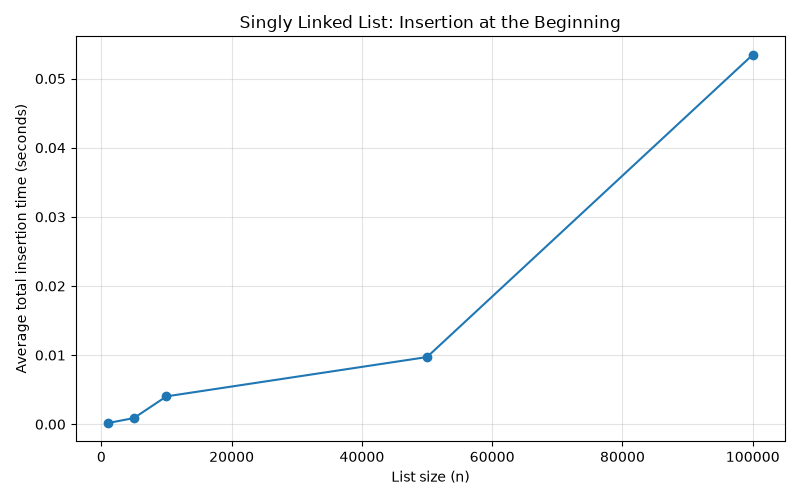

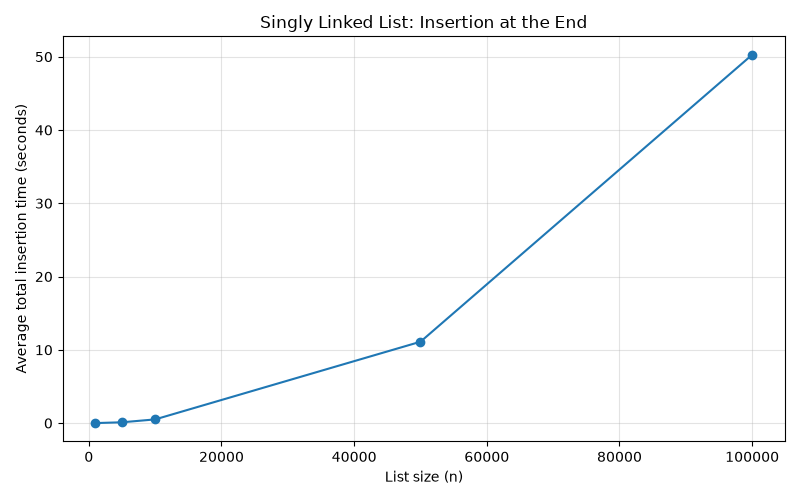

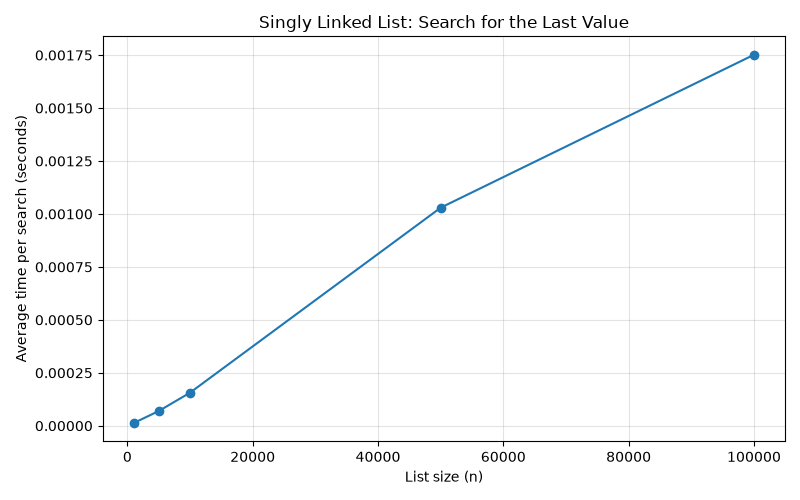

In [8]:
for name, title, ylabel in [
    ('Insert front', 'Singly Linked List: Insertion at the Beginning', 'Average total insertion time (seconds)'),
    ('Insert end', 'Singly Linked List: Insertion at the End', 'Average total insertion time (seconds)'),
    ('Search', 'Singly Linked List: Search for the Last Value', 'Average time per search (seconds)'),
]:
    plt.figure(figsize=(8, 5))
    plt.plot(sizes, average_times[name], marker='o')
    plt.xlabel('List size (n)')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.35)
    plt.tight_layout()
    plt.show()


### Part C - Complexity Analysis

Worst-case time for a list of length `n`:

| Operation | Singly linked list | Doubly linked list |
|---|---:|---:|
| Insert at beginning | `Θ(1)` | `Θ(1)` |
| Insert at end | `Θ(n)` | `Θ(1)` |
| Delete first node | `Θ(1)` | `Θ(1)` |
| Delete last node | `Θ(n)` | `Θ(1)` |
| Search by value | `Θ(n)` | `Θ(n)` |
| Traverse all nodes | `Θ(n)` | `Θ(n)` |

The singly linked list maintains only head; the doubly linked list maintains head and tail. No index or lookup structure is used. For deletion of the last node, the list is nonempty. A one-node list takes constant time, while the singly linked worst case grows linearly with `n` because the predecessor must be found.

The doubly linked search bound describes following next references until a match or the end, even though a separate search method is not needed in Task 2. `INSERT_AFTER` and `DELETE_VALUE` in Task 1 also take `Θ(n)` worst-case time because locating the first match requires traversal. Once the relevant nodes are known, changing links takes `Θ(1)` time.

Each insertion needs `Θ(1)` additional space for one new node. Deletion and search use `Θ(1)` working space. A list of `n` nodes occupies `Θ(n)` total storage. The `contents` helpers and the returned display strings use `Θ(n)` additional space for reporting.

### Part D - Arrays vs. Linked Lists

| Property | Array | Singly linked list |
|---|---|---|
| Direct access by index | `Θ(1)` | `Θ(n)` worst case |
| Insertion at beginning | `Θ(n)` to shift elements | `Θ(1)` |
| Insertion at end | `Θ(1)` with available space and known length | `Θ(n)` without tail |
| Search in unsorted data | `Θ(n)` worst case | `Θ(n)` worst case |
| Additional pointer memory | No per-element link references | One next reference per node, plus head |
| Contiguous storage required | Yes, for array slots | No, nodes can be allocated separately |

The array has fixed capacity with available space, and insertion preserves the existing order without maintaining sorted order. The linked list has only a head pointer. Python lists store a contiguous array of object references, while the referenced integer objects can be elsewhere in memory; the array comparison concerns the slots themselves. A Python node also has object overhead beyond its data and next fields.


### Part E - Discussion

1. **Why is front insertion efficient?** The new node points to the old head, and head is replaced by the new node. No existing element is moved or searched for.
2. **Why can end insertion be expensive?** Without tail, the list must be followed from head to find the last node. Building `n` elements this way takes `Θ(1 + 2 + ... + n) = Θ(n²)` total time.
3. **Effect of a tail pointer:** End insertion becomes `Θ(1)`, so building the list becomes `Θ(n)`. Tail must be updated when the list becomes empty or its last node changes. A tail alone does not make singly linked last-node deletion constant time, because its predecessor is still needed.
4. **Why is search linear?** The next reference only identifies the adjacent node. With no extra index, finding a value generally requires checking nodes one at a time.
5. **Why is array indexing efficient?** The address of a fixed-width array slot can be computed from the base address and index. No traversal of earlier elements is needed.
6. **When prefer a linked list?** It is useful when the size changes frequently, front insertion/deletion is common, or nodes are inserted and removed near already known positions. Arrays are usually preferable when indexed access and cache locality are important. Searching for a position first can remove a linked list's insertion advantage.
7. **Measurements and theory:** The front-insertion batch should grow approximately linearly, the head-only end-insertion batch quadratically, and one search for the last value linearly. At each size, that search checks exactly `n` nodes. The normalized measurements below compare `front time / n`, `end time / n²`, and `search time / n`; approximately steady values support these bounds. The end-insertion results show the clearest quadratic growth. Front-insertion times vary more after normalization because these shorter measurements include node allocation and occasional garbage collection. Search times also reflect changes in cache behavior as the list grows. Interpreter overhead and system scheduling can change the exact ratios between sizes.


In [9]:
print('Measured time normalized by the theoretical growth term')
print(f"{'n':>8} {'Front / n (ns)':>20} {'End / n^2 (ns)':>20} {'Search / n (ns)':>20}")
print('-' * 71)
for index, n in enumerate(sizes):
    front_normalized = average_times['Insert front'][index] * 1e9 / n
    end_normalized = average_times['Insert end'][index] * 1e9 / (n * n)
    search_normalized = average_times['Search'][index] * 1e9 / n
    print(f'{n:>8} {front_normalized:>20.2f} {end_normalized:>20.2f} {search_normalized:>20.2f}')


Measured time normalized by the theoretical growth term
       n       Front / n (ns)       End / n^2 (ns)      Search / n (ns)
-----------------------------------------------------------------------
    1000               169.97                 4.33                12.70
    5000               179.80                 4.50                13.89
   10000               403.50                 5.07                15.62
   50000               194.44                 4.44                20.59
  100000               534.52                 5.03                17.52


## Additional Theoretical Questions

1. **Dynamic memory allocation:** Memory is requested while a program runs. Here, calling `Node(value)` or `DoublyNode(value)` creates a new node when insertion is needed, rather than reserving one fixed-size array in advance.
2. **Pointer versus node:** A node is an object containing data and links. A pointer or reference identifies a node and allows another object or variable to access it. Several references can identify the same node.
3. **Dangling pointer:** A pointer that still refers to memory after the referenced object has been deallocated. In ordinary Python code, a strong reference keeps an object alive, so deleting a node from the list does not invalidate other strong references to that object.
4. **Memory leak:** Memory that remains allocated even though the program no longer needs it. Retaining references to unused nodes can prevent their collection. A leak is different from temporary delayed reclamation by a garbage collector.
5. **Why manage memory carefully?** Insertion must preserve the existing chain, and deletion must reconnect neighbors and update head or tail. Clearing removed links avoids retaining other nodes unnecessarily. In CPython, reference counting usually reclaims objects when their last reference disappears; cyclic garbage collection also handles unreachable cycles. This matters for doubly and circular linked lists. Objects still reachable from a variable are not garbage, and collection timing is not guaranteed. The Josephus function removes the final node after saving the survivor, leaving its local circle empty.
6. **Linked stack:** Use head as the top. Push inserts at head, pop removes head, and peek reads head's data. All three operations take `Θ(1)` time.
7. **Linked queue:** Maintain head and tail. Enqueue adds after tail, and dequeue removes head, both in `Θ(1)` time. Enqueuing into an empty queue initializes both references; removing the final node clears both.
8. **Three list types:** A singly linked list stores next references and ends at `None`. A doubly linked list also stores prev references for backward traversal. A circular list connects the last node back to the first and needs a full-cycle stopping condition. Circularity and backward links are separate properties: a circular list can be singly or doubly linked.


## Conclusion

A singly linked list uses one link per node and supports constant-time insertion and deletion at the beginning. Without a tail pointer, insertion at the end requires traversal. A doubly linked list uses more reference storage but allows backward traversal and constant-time deletion at either end. A circular list continues from the last node to the first, which makes repeated counting in the Josephus problem straightforward.

The operation traces show how head, tail, and node connections change. The Josephus tests give the required survivors, and the timing experiments compare front insertion, end insertion, and search under the stated head-only representation. The appropriate structure depends on the operations needed: fast access by index favors an array, while local changes around known nodes favor linked lists.
